Python     : 3.12.7
TensorFlow : 2.21.0
Keras      : 3.15.1
NumPy      : 2.5.4
Matplotlib : 3.11.2
Cihazlar   : [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Conv testi : (1, 28, 28, 1) -> (1, 26, 26, 8)
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 3us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Eğitim     : (60000, 28, 28) | Test: (10000, 28, 28)


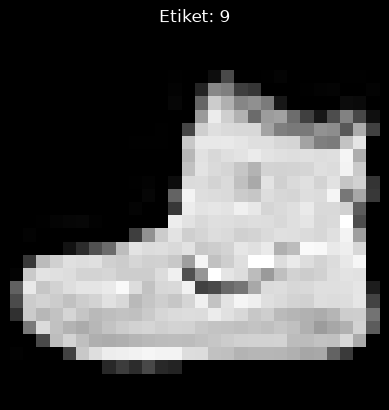

In [2]:
# kurdugum ortam düzgün çalışıp çalışmıyor mu diye bir test scripti yani ödeve ait bir şey değiş

import sys
import numpy as np
import tensorflow as tf
import matplotlib
import matplotlib.pyplot as plt

# 1) Sürümler
print("Python     :", sys.version.split()[0])
print("TensorFlow :", tf.__version__)
print("Keras      :", tf.keras.__version__)
print("NumPy      :", np.__version__)
print("Matplotlib :", matplotlib.__version__)

# 2) Cihaz (Windows'ta sadece CPU görünmesi normaldir)
print("Cihazlar   :", tf.config.list_physical_devices())

# 3) Küçük bir konvolüsyon testi
x = tf.random.normal((1, 28, 28, 1))
y = tf.keras.layers.Conv2D(8, (3, 3), activation="relu")(x)
print("Conv testi :", x.shape, "->", y.shape)   # beklenen: (1, 26, 26, 8)

# 4) Fashion-MNIST indirme testi (ilk seferde internetten iner)
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
print("Eğitim     :", x_train.shape, "| Test:", x_test.shape)  # beklenen: (60000, 28, 28) | (10000, 28, 28)

# 5) Grafik testi
plt.imshow(x_train[0], cmap="gray")
plt.title(f"Etiket: {y_train[0]}")
plt.axis("off")
plt.show()

In [1]:
import tensorflow as tf
import numpy as np

# Rastgelelik kontrolü
tf.keras.utils.set_random_seed(42)

# 3x3 boyutunda 16 filtreli konvolüsyon katmanı
conv = tf.keras.layers.Conv2D(
    filters=16,
    kernel_size=(3, 3),
    activation='relu',
    kernel_initializer='he_normal'
)

# Örnek giriş görüntüsü
dummy_input = tf.random.normal((1, 128, 128, 1))

# Konvolüsyon işlemi
output = conv(dummy_input)

# Ağırlıkları al
weights, biases = conv.get_weights()

print("Giriş boyutu:", dummy_input.shape)
print("Çıkış boyutu:", output.shape)
print("Filtre ağırlıklarının boyutu:", weights.shape)
print("Bias boyutu:", biases.shape)

# İlk filtrenin ağırlıkları
print("İlk filtre:")
print(weights[:, :, 0, 0])

Giriş boyutu: (1, 128, 128, 1)
Çıkış boyutu: (1, 126, 126, 16)
Filtre ağırlıklarının boyutu: (3, 3, 1, 16)
Bias boyutu: (16,)
İlk filtre:
[[-0.25283593  0.12861036 -0.75786656]
 [-0.21681367 -0.15182823 -0.702172  ]
 [ 0.23038778  0.76512676 -0.74278826]]


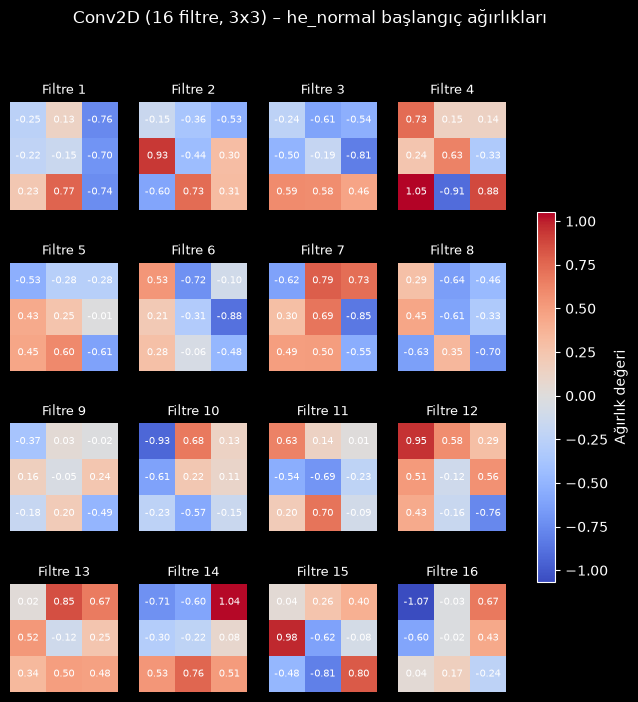

Ağırlık ortalaması : 0.017164346
Ağırlık std sapması: 0.51928467
Teorik he_normal std ≈ sqrt(2/9) = 0.4714045207910317


In [3]:
# Bu kod ödev dökümanında yoktu bunu ben kendim yazdırdım amaç bütün filtrelerin başlangıç ağırlıklarını görselleştirmek
# bu yüzden tam görsellik sağlaması için bu py scriptini yazdırdım.

import matplotlib.pyplot as plt

vmin, vmax = weights.min(), weights.max()   # tüm filtreler aynı renk ölçeğinde

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    w = weights[:, :, 0, i]                 # i. filtrenin 3x3 ağırlıkları
    im = ax.imshow(w, cmap='coolwarm', vmin=vmin, vmax=vmax)
    for (r, c), val in np.ndenumerate(w):   # değerleri hücrelerin üzerine yaz
        ax.text(c, r, f"{val:.2f}", ha='center', va='center', fontsize=7)
    ax.set_title(f"Filtre {i + 1}", fontsize=9)
    ax.axis('off')

fig.colorbar(im, ax=axes, shrink=0.6, label='Ağırlık değeri')
fig.suptitle("Conv2D (16 filtre, 3x3) – he_normal başlangıç ağırlıkları")
plt.savefig("bolum3_filtreler.png", dpi=150, bbox_inches='tight')
plt.show()

print("Ağırlık ortalaması :", weights.mean())
print("Ağırlık std sapması:", weights.std())
print("Teorik he_normal std ≈ sqrt(2/9) =", np.sqrt(2 / 9))

###  SIRA SIRA ADIM ADIM KODLARIN CEVAPLARI

#### İlk Kodda kullanılan 16 filtre ne anlama geliyor

Katmanın 16 farklı özellik dedektörü öğreneceği anlamına gelir. Her filtre görüntü üzerinde ayrı ayrı kaydırılır ve kendi özellik haritasını yani feature map'i üretir. Bu yüzden çıkışın kanal sayısı 16'dır.

#### Her filtrenin boyutu nedir sorusuna yanıt olarak

3×3×1. Uzamsal boyut `kernel_size=(3, 3)` ile belirlendi; derinlik ise giriş kanal sayısına eşittir. Giriş gri seviye ki gri seviyede kanal sayısı 1 olduğu için derinlik 1'dir. Her filtrede 3 × 3 × 1 = 9 ağırlık vardır buna önce değinmiştim zaten.

#### weights değişkeninin boyutunu açıklayorum

`(3, 3, 1, 16)` → (kernel yüksekliği, kernel genişliği, giriş kanal sayısı, filtre sayısı) ordaki parametrelerin anlamları.
Toplam 3 × 3 × 1 × 16 = **144** ağırlık vardır. `weights[:, :, 0, i]` ifadesi i. filtrenin 3×3'lük ağırlık matrisini verir.

#### biases değişkeninin boyutunu açıklamak gerekirse

öncekikle bias, filtrenin çıktısını kaydırarak hangi güçteki eşleşmelerde aktifleşeceğini belirleyen, öğrenilebilir bir eşik parametresidir.

`(16,)` → her filtre için bir bias değeri. Bias, filtrenin hesapladığı toplama eklenen sabit bir terimdir ve Keras'ta varsayılan olarak 0 ile başlatılır.
Katmanın toplam parametre sayısı 144 + 16 = **160**'tır.

Neden her bir filtre için ayrı bir bias vardır gibi bir soru akıllara geliyor burda onu da açıklayayım:
Ağırlık gibi biasta paylaşılır filtre görüntünün her konumuna aynı biası ekler çünkü bir filtre görüntünün her yerinde aynı örüntüyü arar eşiğininde her yerde olması mantıklıdır

#### Giriş boyutu 128×128 iken çıkış boyutu neden değişmiştir hemen açıklıyorum

Çıkış `(1, 126, 126, 16)` olmuştur. İki değişiklik vardır:

- **Uzamsal boyut 128 → 126:** Varsayılan `padding='valid'` olduğundan görüntünün kenarlarına dolgu yapılmıyor. 3×3'lük filtre yalnızca tamamen görüntünün içine sığdığı konumlarda hesaplanabilir sığmadığı taşıtığı durumlara yapacak bişey yok; bu yüzden her kenardan 1 piksel kaybedilir. tabi stride ile de alakalıdır bu durum

      çıkış = (giriş − kernel) / stride + 1 = (128 − 3) / 1 + 1 = 126
      - totalde 2 piksellik bir kayıp oluyor

- **Kanal sayısı 1 → 16:** Her filtre bir çıkış kanalı ürettiği için.

`padding='same'` kullanılsaydı kenarlara sıfır eklenir ve çıkış 128×128 olarak kalırdı.

#### kernel_initializer='he_normal' ne anlama geliyo

he_normal başlangıç degerlerini belirleyen bir yöntem en basit tanımıyla

peki madem böyle neden en başta sıfır yapmadık diye aklımıza gelebiyor eger hepsini sıfır yapsaydık 16 filtrede birbirinin aynısı olacaktı aynı girişe aynı cevabı vereceklerdi. Çok büyük olamaz olursa her katman değerleri büyütür katmanlar ilerledikçe de sayılar patlar eğitim bozulur
Aynı şekilde çok küçükte olamaz bu seferde sıfıra yaklaşır bişey öğrenilmez işte he_normal bunu otomatik bi şekilde ayatlıyor
KISACA: he_normal ağırlıkları rastgele ama doğru büyüklükte başlatır böylece sinyal katmanlar boyunca ne patlar ne de söner ve relu ile birlikte eğitim düzgün başlar

MERAKLILARI İÇİN AŞAĞIYA FORMÜLÜNÜ BİLİMSEL AÇIKLAMASINI FALAN KOYDUM biraz kafa karıştırıcı
Filtre ağırlıklarının başlangıç değerlerinin **He (Kaiming) normal** yöntemiyle belirleneceğini ifade eder. Ağırlıklar, ortalaması 0 ve standart sapması √(2 / fan_in) olan kesik (truncated) normal dağılımdan rastgele çekilir. fan_in, bir nörona gelen giriş sayısıdır; burada 3 × 3 × 1 = 9 olduğu için standart sapma √(2/9) ≈ **0,47**'dir.

Bu yöntem ReLU ile kullanılmak üzere tasarlanmıştır. ReLU negatif değerleri sıfırladığı için sinyalin varyansı yaklaşık yarıya düşer; He başlatma bunu formüldeki 2 katsayısıyla telafi eder. Böylece katmanlar boyunca sinyal ve gradyanlar ne sönümlenir ne de patlar, eğitim daha kararlı başlar.

#### Bütün filtrelerin başlangıç ağırlıklarını görselleştirmek gerekirse

Yukarıdaki şekilde 16 filtrenin başlangıç ağırlıkları görülmektedir. Kırmızı tonlar pozitif, mavi tonlar negatif ağırlıkları gösterir klasik soğuk renk sıcak renk olayı. Ağırlıklar rastgele başlatıldığı için filtreler belirli bir örüntü göstermez gürültü gibi görünür. Bu filtreler eğitim sırasında veriye göre güncellenerek anlamlı özellik dedektörlerine dönüşür. Ölçülen ortalama ve standart sapma, he_normal dağılımının teorik değerleriyle uyumludur.

In [4]:
# Pooling İşleminin İncelenmesi

import tensorflow as tf

# Örnek giriş matrisi
input_data = tf.constant([
    [[1., 3., 2., 4.],
     [5., 6., 1., 2.],
     [7., 2., 8., 3.],
     [4., 1., 5., 9.]]
])

# Boyutları düzenle: Batch, Height, Width, Channels
input_data = tf.reshape(input_data, (1, 4, 4, 1))

pool = tf.keras.layers.MaxPooling2D(
    pool_size=(2, 2),
    strides=2
)

output = pool(input_data)

print("Giriş:")
print(input_data.numpy()[0, :, :, 0])
print("Pooling sonucu:")
print(output.numpy()[0, :, :, 0])

Giriş:
[[1. 3. 2. 4.]
 [5. 6. 1. 2.]
 [7. 2. 8. 3.]
 [4. 1. 5. 9.]]
Pooling sonucu:
[[6. 4.]
 [7. 9.]]


### ÜSTTEKİ KODUN AÇIKLAMASI VE SORULARIN CEVAPLARI

#### Giriş matrisini incelemek gerekirse

Giriş tek kanallı 4×4lük bir matristir

    1  3  2  4
    5  6  1  2
    7  2  8  3
    4  1  5  9

Keras görüntüleri (görüntü sayısı, satır, sütun, kanal) şeklinde bekler. Bu yüzden 4×4'lük matris (1, 4, 4, 1) şekline getirilmiştir 1 görüntü 4 satır 4 sütun 1 kanal Sayılar değişmemiş sadece Kerasın anlayacağı şekle sokulmuştur

Daha detaylı anlatacak olursam Keras katmanları veriyi `(batch, yükseklik, genişlik, kanal)` biçiminde beklediği için matris `tf.reshape` ile `(1, 4, 4, 1)` boyutuna getirilmiştir: 1 örnek, 4×4 boyut, 1 kanal.

#### 2. Her 2×2 bölgedeki en büyük sayıyı bulunuz.

Matris örtüşmeyen dört adet 2×2 bloğa ayrılır:

| Bölge   | Değerler   | En büyük   |
|---------|------------|------------|
| Sol üst | 1, 3, 5, 6 | **6**      |
| Sağ üst | 2, 4, 1, 2 | **4**      |
| Sol alt | 7, 2, 4, 1 | **7**      |
| Sağ alt | 8, 3, 5, 9 | **9**      |

Elle hesaplanan sonuç:

    6  4
    7  9

#### 3. Programın ürettiği sonucu elle hesapladığınız sonuçla karşılaştırınız.

Programın ürettiği çıktı `[[6, 4], [7, 9]]` olup elle hesaplanan sonuçla birebir aynıdır. Bu, `MaxPooling2D` katmanının her 2×2'lik bloktan yalnızca en büyük değeri seçtiğini ve diğer değerleri attığını doğrular.

#### 4. Giriş ve çıkış matrislerinin boyutlarını açıklayınız.

Bu kısım daha önce de geçmişti;

- Giriş: `(1, 4, 4, 1)`
- Çıkış: `(1, 2, 2, 1)`

`pool_size=(2, 2)` ve `strides=2` olduğu için pencere bloklar örtüşmeyecek şekilde 2'şer adım kayar. Bu yüzden yükseklik ve genişlik yarıya inmiştir:

    Önceden anlattıgım formulun aynısı oluyor bu şekilde
    çıkış = (giriş − pool_size) / stride + 1 = (4 − 2) / 2 + 1 = 2

Batch (1) ve kanal (1) boyutları değişmemiştir. Eleman sayısı 16'dan 4'e, yani %75 azalmıştır.

#### 5. Max Pooling kullanılmasının CNN açısından avantajı nedir?

- **Boyut ve hesaplama azalır:** 4×4lük matris 2×2ye indi yani 16 sayı yerine 4 sayı kaldı sonraki katmanların işleyeceği veri 4 kat azaldı bu da daha az hesaplama daha az maliyet demek
- **Önemli bilgi korunur:** Her bölgedeki en güçlü aktivasyon, yani en belirgin özellik tutulur.
- **Küçük kaymalara dayanıklılık:** Bir özellik bölge içinde bir piksel kaysa bile maksimum değer genellikle değişmez bu da çok hassas olmasını engeller.
- **Daha geniş algılama alanı:** Sonraki konvolüsyon katmanları orijinal görüntünün daha büyük bir bölgesini görür.
- **Ek parametre yoktur:** Öğrenilecek ağırlığı olmadığı için modeli büyütmez ve overfitting riskini artırmaz.

In [6]:
# ReLU ve Softmax Fonksiyonlarının İncelenmesi kısmı
import tensorflow as tf

x = tf.constant([-5., -2., -1., 0., 2., 4., 6.])

relu = tf.keras.layers.ReLU()
y = relu(x)

print("Giriş:", x.numpy())
print("ReLU çıkışı:", y.numpy())

Giriş: [-5. -2. -1.  0.  2.  4.  6.]
ReLU çıkışı: [0. 0. 0. 0. 2. 4. 6.]


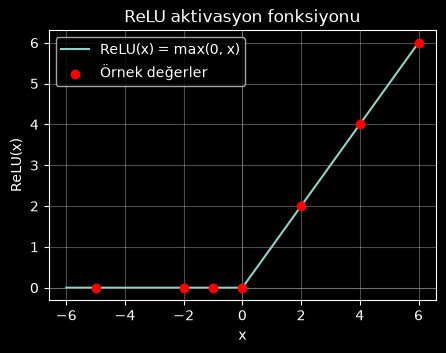

In [7]:
# grafiği çizmesi için daha anlaşılır olması için ben eklettim bu kısmı
# hocamızın derste çizdiği grafiğin aynısı zaten
import numpy as np
import matplotlib.pyplot as plt

xs = np.linspace(-6, 6, 200)
plt.figure(figsize=(5, 3.5))
plt.plot(xs, np.maximum(0, xs), label='ReLU(x) = max(0, x)')
plt.scatter(x.numpy(), y.numpy(), color='red', zorder=3, label='Örnek değerler')
plt.axhline(0, color='gray', lw=0.5)
plt.axvline(0, color='gray', lw=0.5)
plt.title("ReLU aktivasyon fonksiyonu")
plt.xlabel("x")
plt.ylabel("ReLU(x)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### ÜSTTEKİ KODUN AÇIKLAMASI VE SORULARIN CEVAPLARI

#### 1. Negatif değerler neden sıfırlanmıştır?

Bu tamamen relu ile alaklı bir durum. relunun kuralı `ReLU(x) = max(0, x)`'tir, yani 0 ile x'ten büyük olanı seçer. x negatifse büyük olan 0 olduğu için sonuç 0 olur. Bu yüzden −5, −2 ve −1 değerleri 0'a dönüşmüştür. 0 değeri de 0 olarak kalmıştır.

Anlamı şudur: bir nöronun değeri negatifse, aradığı özellik o bölgede yoktur ve nöron "kapalı" kalır. Böylece her girişte nöronların yalnızca bir kısmı çalışır; bu da modeli daha sade ve verimli yapar.

#### 2. Pozitif değerler neden korunmuştur?

x pozitifse 0 ile x ten büyük olan x in kendisidir yani değer olduğu gibi geçer Bu yüzden 2, 4 ve 6 değişmemiştir.

Böylece özelliğin ne kadar güçlü bulunduğu bilgisi kaybolmaz: 6, 2'den daha güçlü bir sinyal olarak kalır Ayrıca bu bölgede ReLU'nun eğimi 1'dir. Eğitim sırasında hatayı geriye doğru taşıyan sinyal bu bölgeden küçülmeden geçer ve öğrenme yavaşlamaz.

#### 3. ReLU kullanılmasaydı ne gibi bir farklılık oluşabilirdi?

- **Hiç aktivasyon fonksiyonu kullanılmasaydı:** Her katman sadece çarpma ve toplama yapardı (doğrusal işlem). Art arda yapılan doğrusal işlemler tek bir doğrusal işleme eşittir yani sadece lineerlik olurdu. Bu durumda katman eklemenin bir faydası olmaz ve model karmaşık şekilleri, örneğin bir ayakkabının şeklini, öğrenemezdi.
- **ReLU yerine Sigmoid veya Tanh kullanılsaydı:** Model karmaşık şekilleri öğrenebilirdi, ama bu fonksiyonlar çok büyük ya da çok küçük girişlerde düzleşir ve eğimleri sıfıra yaklaşır. Derin ağlarda bu, hatayı geriye taşıyan sinyalin katman katman küçülüp kaybolmasına yol açar yani kaybolan gradyan sorunu dediğimiz şeye yol açar ve eğitim yavaşlar. Ayrıca bu fonksiyonları hesaplamak ReLU'dan daha maliyetlidir.

In [9]:
# Softmax kısmı
import tensorflow as tf

logits = tf.constant([[2.0, 1.0, 0.1]])

softmax = tf.keras.layers.Softmax()
probabilities = softmax(logits)

print("Softmax sonuçları:")
print(probabilities.numpy())

print("Olasılıkların toplamı:")
print(tf.reduce_sum(probabilities).numpy())

Softmax sonuçları:
[[0.6590011  0.24243298 0.09856588]]
Olasılıkların toplamı:
0.99999994


### ÜSTTEKİ KODUN AÇIKLAMASI VE SORULARIN CEVAPLARI

#### 1. Softmax hangi amaçla kullanılır?

Modelin son katmanında üretilen ham puanları olasılıklara dönüştürmek için kullanılır. Böylece modelin her sınıf için ne kadar emin olduğu yüzde olarak görülebilir. Çok sınıflı sınıflandırmada (bizim modelde 10 giysi sınıfı) çıkış katmanında kullanılır.

#### 2. Çıktıdaki değerler neyi ifade etmektedir?

Çıktı yaklaşık `[0.659, 0.242, 0.099]`'dur. Bu değerler girişin sırasıyla 0., 1. ve 2. sınıfa ait olma olasılığıdır:

- 0. sınıf: %65,9
- 1. sınıf: %24,2
- 2. sınıf: %9,9

En büyük puan (2.0) en büyük olasılığı almıştır, yani sıralama korunmuştur. Ancak puanlar arasındaki farklar büyümüştür: 2.0 ile 1.0 arasındaki 1 puanlık fark, olasılıkta yaklaşık 2,7 katlık bir farka dönüşmüştür.

Elle hesaplama:

    e^2.0 ≈ 7.389
    e^1.0 ≈ 2.718
    e^0.1 ≈ 1.105
    Toplam ≈ 11.212

    7.389 / 11.212 ≈ 0.659
    2.718 / 11.212 ≈ 0.242
    1.105 / 11.212 ≈ 0.099

#### 3. Olasılıkların toplamı neden 1'dir?

Softmax her değeri, bütün değerlerin toplamına böler aşağıda formülü bu şekilde:

    softmax(z_i) = e^(z_i) / (e^(z_1) + e^(z_2) + ... + e^(z_n))

Bir bütünü parçalarına böldüğümüzde parçaların toplamı her zaman bütüne eşittir; bir pastayı dilimlere ayırmak gibi. Bu yüzden çıktıların toplamı her zaman 1'dir. Ayrıca e üzeri herhangi bir sayı her zaman pozitif olduğu için tüm değerler 0 ile 1 arasında kalır. Bu iki özellik, çıktının geçerli bir olasılık dağılımı olmasını sağlar.

#### 4. En yüksek olasılığa sahip sınıf nasıl belirlenir?

Olasılıklar arasındaki en büyük değerin sırası bulunur. Bu işleme **argmax** denir. argmax en büyük deger kaçıncı sırada sorusunun cevabıdır

Bu örnekte `argmax([0.659, 0.242, 0.099]) = 0` olur, yani model girişi 0. sınıfa atar. Kodda `np.argmax(...)` ile yapılır.

In [11]:
# Basit Bir CNN Modeli Oluşturulması

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

# Normalizasyon
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Kanal boyutu ekleme
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Eğitim verisi:", x_train.shape)
print("Test verisi:", x_test.shape)

Eğitim verisi: (60000, 28, 28, 1)
Test verisi: (10000, 28, 28, 1)


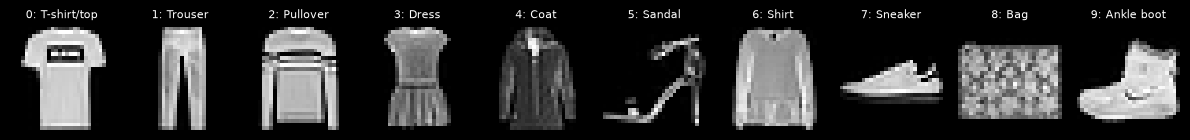

In [12]:
# Her sınıftan bir örnek resim gösteriliyor “veri seti neye benziyor” sorusunun cevabı

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

plt.figure(figsize=(12, 3))
for c in range(10):
    idx = np.where(y_train == c)[0][0]      # c sınıfının ilk örneği
    plt.subplot(1, 10, c + 1)
    plt.imshow(x_train[idx, :, :, 0], cmap='gray')
    plt.title(f"{c}: {class_names[c]}", fontsize=8)
    plt.axis('off')
plt.tight_layout()
plt.show()

#### Kodun açıklaması

- **Veri yükleme:** Fashion-MNIST, Keras içinde hazır gelir. `load_data()` veriyi eğitim (`x_train`, `y_train`) ve test (`x_test`, `y_test`) olarak ikiye ayırır. `x` resimleri, `y` etiketleri tutar.
- **Normalizasyon:** Piksel değerleri 0–255 arasındadır. 255'e bölünerek 0–1 arasına çekilmiştir. Küçük ve aynı ölçekteki sayılarla model daha hızlı ve kararlı öğrenir.
- **Kanal boyutu ekleme:** Veri `(60000, 28, 28)` şeklindeydi. Conv2D katmanı, 4. Bölüm'de gördüğümüz gibi `(görüntü sayısı, satır, sütun, kanal)` biçiminde veri bekler. `np.newaxis` ile sona kanal boyutu eklenmiş ve veri `(60000, 28, 28, 1)` olmuştur: 60.000 görüntü, 28×28, 1 kanal (gri).

In [13]:
# CNN mimarisinin oluşturulması bunlar direk dökümanda verilenler

tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # Birinci konvolüsyon
    tf.keras.layers.Conv2D(
        8, (3, 3),
        activation='relu'
    ),

    # Birinci pooling
    tf.keras.layers.MaxPooling2D((2, 2)),

    # İkinci konvolüsyon
    tf.keras.layers.Conv2D(
        16, (3, 3),
        activation='relu'
    ),

    # İkinci pooling
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Çok boyutlu özellikleri tek boyuta dönüştür
    tf.keras.layers.Flatten(),

    # Tam bağlantılı katman
    tf.keras.layers.Dense(64, activation='relu'),

    # 10 sınıf için çıktı
    tf.keras.layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        25,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,562 (107.66 KB)

 Trainable params: 27,562 (107.66 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# modelin derlenmesi ve eğitilmesi aşaması

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7696 - loss: 0.6288 - val_accuracy: 0.8203 - val_loss: 0.4840
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8468 - loss: 0.4236 - val_accuracy: 0.8432 - val_loss: 0.4283
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8642 - loss: 0.3764 - val_accuracy: 0.8600 - val_loss: 0.3908
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8750 - loss: 0.3461 - val_accuracy: 0.8665 - val_loss: 0.3622
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8819 - loss: 0.3249 - val_accuracy: 0.8728 - val_loss: 0.3431
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8691 - loss: 0.3645
Test Loss: 0.36452171206474304
Test Accuracy: 0.8690999746322632


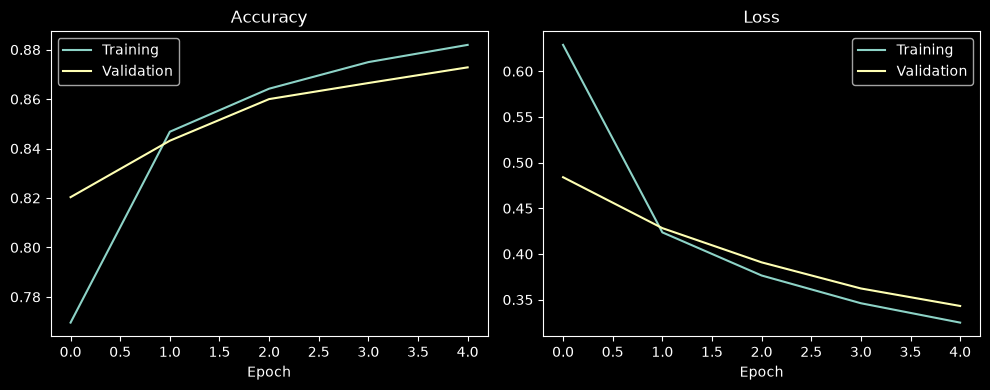

In [15]:
# Eğitim sonuçlarının görselleştirilmesi için bu kod var

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.savefig("bolum6_egitim_grafikleri.png", dpi=150, bbox_inches='tight')
plt.show()

#### Eğitim sonuçlarının yorumu

Model 5 epoch boyunca eğitilmiştir. Son epoch'ta eğitim doğruluğu **%88,19**, doğrulama doğruluğu **%87,28** olmuştur. Test verisi üzerinde **%86,91 test doğruluğu** ve **0,3645 test kaybı** elde edilmiştir. Yani model, eğitim sırasında hiç görmediği 10.000 giysi resminin yaklaşık 8.691'ini doğru sınıflandırmıştır.

Grafiklerde eğitim ve doğrulama doğruluğu her epoch'ta artmış, kayıp ise azalmıştır. Eğitim doğruluğu ile test doğruluğu arasındaki fark yaklaşık 1,3 puandır. Bu küçük fark, modelin eğitim verisini ezberlemediğini (overfitting olmadığını) ve öğrendiklerini yeni verilere genelleyebildiğini göstermektedir.

### UFAK BİR ÖZET

Resim (28×28×1)
  - → Conv1: 8 basit özellik ara (kenar, köşe)        → 26×26×8
  - → Pool1: küçült                                   → 13×13×8
  - → Conv2: 16 karmaşık özellik ara (doku, parça)    → 11×11×16
  - → Pool2: küçült                                   → 5×5×16
  - → Flatten: tek sıraya diz                         → 400
  - → Dense(64): özellikleri birleştir                → 64
  - → Dense(10): her sınıfa puan ver + Softmax        → 10 olasılık

## 7. Bölüm: Model Mimarisinin Anlaşılması

### Katman katman boyut ve parametre analizi

| Katman                  | Çıkış boyutu   | Parametre sayısı   | Hesap             |
|-------------------------|----------------|--------------------|-------------------|
| Input                   | 28×28×1        | 0                  | –                 |
| Conv2D (8 filtre, 3×3)  | 26×26×8        | 80                 | 8 × (3×3×1) + 8   |
| MaxPooling2D (2×2)      | 13×13×8        | 0                  | –                 |
| Conv2D (16 filtre, 3×3) | 11×11×16       | 1.168              | 16 × (3×3×8) + 16 |
| MaxPooling2D (2×2)      | 5×5×16         | 0                  | –                 |
| Flatten                 | 400            | 0                  | 5×5×16            |
| Dense (64)              | 64             | 25.664             | 400 × 64 + 64     |
| Dense (10)              | 10             | 650                | 64 × 10 + 10      |
| **Toplam**              |                | **27.562**         |                   |

Parametre hesabının mantığı: her filtrenin ağırlık sayısı, filtre sayısıyla çarpılır; sonra her biri için 1 bias eklenir.

### ÜSTTEKİ TABLONUN AÇIKLAMASI VE SORULARIN CEVAPLARI

#### 1. Modelde kaç adet konvolüsyon katmanı vardır?

İki adet: 8 filtreli birinci `Conv2D` ve 16 filtreli ikinci `Conv2D`.

#### 2. İlk konvolüsyon katmanında neden 8 filtre kullanılmıştır?

İlk katman ham piksellere bakar ve kenar köşe çizgi gibi basit özellikleri öğrenir Basit özelliklerin çeşidi azdır Ayrıca Fashion-MNIST küçük 28x28lik gri ve görece basit bir veri setidir. Bu yüzden 8 filtre yeterlidir ve modeli küçük ve hızlı tutar.

Bu sayı kesin bir kural değildir; tasarımcının seçtiği ve denemeyle ayarlanan bir değerdir. 8. Bölüm'deki deneyde bu sayıyı değiştirmenin etkisini ölçeceğiz.

#### 3. İkinci konvolüsyon katmanında neden 16 filtre kullanılmıştır?

İkinci katman, ilk katmanın bulduğu basit özellikleri birleştirerek doku, kıvrım, yaka, topuk gibi daha karmaşık özellikler öğrenir. Karmaşık özelliklerin çeşidi daha fazla olduğu için daha fazla filtreye ihtiyaç vardır.

Ayrıca pooling resmi küçülttüğü için (26×26 → 13×13) bu katmanda daha fazla filtre kullanmak hesaplama açısından ucuzdur. İlerledikçe filtre sayısını artırmak (8 → 16) CNN'lerde yaygın bir tasarım kalıbıdır: resim küçülürken bakılan özellik sayısı artar.

#### 4. Konvolüsyon katmanlarından sonra görüntü boyutları nasıl değişmiştir?

Kenarlara dolgu yapılmadığı için (`padding='valid'`) her 3×3 konvolüsyon yükseklik ve genişliği 2 azaltır; kanal sayısını ise filtre sayısına eşitler. Her pooling de boyutu yarıya indirir:

    28×28×1  → Conv1 → 26×26×8  → Pool1 → 13×13×8
    13×13×8  → Conv2 → 11×11×16 → Pool2 → 5×5×16

Resmin boyutu 28×28'den 5×5'e inerken kanal sayısı 1'den 16'ya çıkmıştır. 11 tek sayı olduğu için ikinci pooling'de aşağı yuvarlanmış (11 / 2 → 5), son satır ve sütun kullanılmamıştır.

#### 5. Pooling katmanları ne gibi bir katkı sağlamıştır?

Her pooling katmanı resmin boyutunu yarıya indirmiştir (26 → 13, 11 → 5). Bunun en büyük etkisi Dense katmanda görülür:

- Pooling ile: Flatten çıkışı 400 → Dense parametresi **25.664**
- Pooling olmasaydı: Flatten çıkışı 24 × 24 × 16 = 9.216 → Dense parametresi 9.216 × 64 + 64 = **589.888**

Pooling, bu katmanın parametre sayısını yaklaşık 23 kat azaltmıştır. Bu hem eğitimi hızlandırır hem de ezberleme (overfitting) riskini düşürür. Ayrıca pooling, 4. Bölüm'de anlatıldığı gibi en güçlü özellikleri korur, küçük kaymalara karşı dayanıklılık sağlar ve sonraki katmanın resmin daha geniş bir bölgesini görmesine imkân verir. Pooling katmanlarının kendi parametresi yoktur (0).

#### 6. Flatten katmanının çıktısı kaç elemanlıdır?

5 × 5 × 16 = **400** eleman. Flatten, 5×5 boyutundaki 16 özellik haritasını tek sıralı bir listeye dizer.

#### 7. Dense katmanındaki 64 sayısı neyi ifade etmektedir?

Bu katmandaki nöron sayısını ifade eder. Her nöron Flatten'dan gelen 400 değerin tamamına bağlıdır ve bu özelliklerin farklı bir birleşimini öğrenir. Böylece 400 değerlik bilgi, 64 değerlik daha özet bir bilgiye dönüştürülür.

Modeldeki parametrelerin yaklaşık %93'ü (25.664 / 27.562) bu katmandadır. Yani modelin en "ağır" kısmı burasıdır.

#### 8. Son katmanda neden 10 nöron bulunmaktadır?

Fashion-MNIST'te 10 sınıf vardır: T-shirt, pantolon, kazak, elbise, ceket, sandalet, gömlek, spor ayakkabı, çanta ve bot. Her nöron bir sınıfa karşılık gelir ve o sınıfın puanını üretir. Softmax bu 10 puanı, toplamı 1 olan olasılıklara dönüştürür.

#### 9. Softmax çıkışındaki en yüksek değer neyi ifade eder?

Modelin tahmin ettiği sınıfı ve bu tahmine ne kadar güvendiğini gösterir:

- En yüksek değerin **sırası** (argmax) → tahmin edilen sınıf
- En yüksek değerin **kendisi** → modelin bu tahmine güveni

Örneğin çıkışta en yüksek değer 9. sırada ve 0,95 ise model "bu resim %95 ihtimalle bot (Ankle boot)" demektedir.

#### 10. Modelin tahmin başarısını hangi metrikle ölçtünüz?

**Accuracy (doğruluk)** ile ölçülmüştür: doğru tahmin edilen resim sayısının toplam resim sayısına oranı.

    Accuracy = doğru tahmin sayısı / toplam tahmin sayısı

Eğitim sırasında eğitim ve doğrulama verisi için, eğitimden sonra ise `model.evaluate` ile test verisi için hesaplanmıştır. Bu çalışmada test doğruluğu **%86,91** çıkmıştır: model, hiç görmediği 10.000 resmin yaklaşık 8.691'ini doğru sınıflandırmıştır.

Bunun yanında modelin ne kadar yanıldığı kayıp (loss) değeriyle de izlenmiştir. Kayıp fonksiyonu olarak `sparse_categorical_crossentropy` kullanılmıştır; test kaybı 0,3645'tir.

In [16]:
# filtre sayısı deneyi
# Aynı model iki farklı ayarla eğitilmiştir. Yalnızca **ilk konvolüsyon katmanının filtre sayısı** değiştirilmiş, diğer her şey (mimari, optimizer, epoch sayısı, batch size, doğrulama oranı, rastgelelik tohumu) aynı tutulmuştur.


import time

def build_model(first_filters):
    """6. Bölüm'deki modelin aynısı; sadece ilk katmanın filtre sayısı dışarıdan veriliyor."""
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(first_filters, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(16, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])


def run_experiment(first_filters, seed=42):
    tf.keras.backend.clear_session()        # önceki modelden kalanları temizle
    tf.keras.utils.set_random_seed(seed)    # iki deney de aynı başlangıç koşullarıyla

    m = build_model(first_filters)
    m.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

    start = time.perf_counter()             # süre ölçümü başlar
    h = m.fit(x_train, y_train,
              epochs=5, batch_size=64,
              validation_split=0.1, verbose=1)
    elapsed = time.perf_counter() - start   # süre ölçümü biter

    _, test_acc = m.evaluate(x_test, y_test, verbose=0)

    return {
        "filters": first_filters,
        "params": m.count_params(),
        "train_acc": h.history['accuracy'][-1],    # son epoch'un eğitim doğruluğu
        "val_acc": h.history['val_accuracy'][-1],
        "test_acc": test_acc,
        "time": elapsed,
        "history": h.history,
    }


results = []
for f in (8, 16):
    print(f"\n===== Deney: ilk katmanda {f} filtre =====")
    results.append(run_experiment(f))


===== Deney: ilk katmanda 8 filtre =====

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7696 - loss: 0.6288 - val_accuracy: 0.8203 - val_loss: 0.4840
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8468 - loss: 0.4236 - val_accuracy: 0.8432 - val_loss: 0.4283
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8642 - loss: 0.3764 - val_accuracy: 0.8600 - val_loss: 0.3908
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8750 - loss: 0.3461 - val_accuracy: 0.8665 - val_loss: 0.3622
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8819 - loss: 0.3249 - val_accuracy: 0.8728 - val_loss: 0.3431

===== Deney: ilk katmanda 16 filtre =====
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7809 - loss: 0.6118 - val_accuracy: 0.8303 - val_loss: 0.4730
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8547 - loss: 0.4028 - val_accuracy: 0.8580 - val_loss: 0.4013
Epoch 3/5
844/844 ━━━━━━━

In [17]:
# sonuc tablosu daha okunaklı olsun diye ben yazdırdım bunu da

r1, r2 = results
print(f"{'Ölçüt':<22}{'Deney 1':>12}{'Deney 2':>12}")
print("-" * 46)
print(f"{'Filtre sayısı':<22}{r1['filters']:>12}{r2['filters']:>12}")
print(f"{'Parametre sayısı':<22}{r1['params']:>12,}{r2['params']:>12,}")
print(f"{'Eğitim doğruluğu':<22}{r1['train_acc']:>12.4f}{r2['train_acc']:>12.4f}")
print(f"{'Doğrulama doğruluğu':<22}{r1['val_acc']:>12.4f}{r2['val_acc']:>12.4f}")
print(f"{'Test doğruluğu':<22}{r1['test_acc']:>12.4f}{r2['test_acc']:>12.4f}")
print(f"{'Eğitim süresi (sn)':<22}{r1['time']:>12.1f}{r2['time']:>12.1f}")
print(f"{'Eğitim-test farkı':<22}{r1['train_acc']-r1['test_acc']:>12.4f}{r2['train_acc']-r2['test_acc']:>12.4f}")

Ölçüt                      Deney 1     Deney 2
----------------------------------------------
Filtre sayısı                    8          16
Parametre sayısı            27,562      28,794
Eğitim doğruluğu            0.8819      0.8868
Doğrulama doğruluğu         0.8728      0.8778
Test doğruluğu              0.8691      0.8744
Eğitim süresi (sn)            11.4        15.7
Eğitim-test farkı           0.0128      0.0124


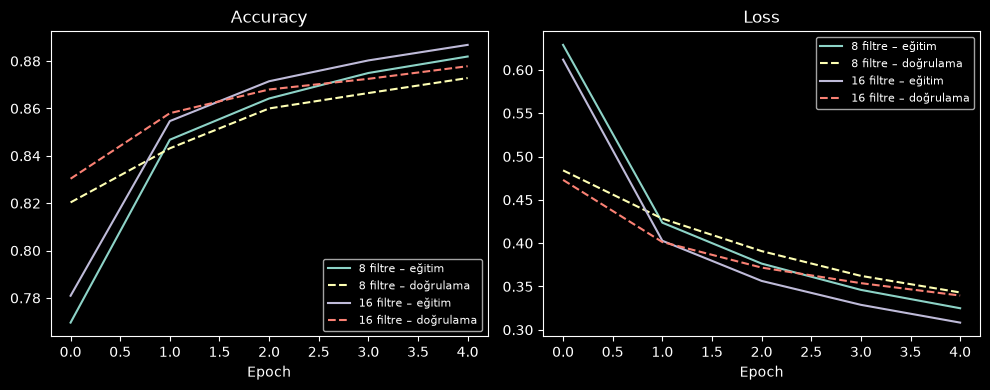

In [18]:
# iki deneyin eğrileri tek grafikte görsel açıdan daha iyi anlaşılacağını düşündüm

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
for r in results:
    plt.plot(r['history']['accuracy'], label=f"{r['filters']} filtre – eğitim")
    plt.plot(r['history']['val_accuracy'], '--', label=f"{r['filters']} filtre – doğrulama")
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend(fontsize=8)

plt.subplot(1, 2, 2)
for r in results:
    plt.plot(r['history']['loss'], label=f"{r['filters']} filtre – eğitim")
    plt.plot(r['history']['val_loss'], '--', label=f"{r['filters']} filtre – doğrulama")
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend(fontsize=8)

plt.tight_layout()
plt.savefig("bolum8_deney_karsilastirma.png", dpi=150, bbox_inches='tight')
plt.show()

### Sonuç tablosu

| Ölçüt               | Deney 1   | Deney 2   |
|---------------------|-----------|-----------|
| Filtre sayısı       | 8         | 16        |
| Parametre sayısı    | 27.562    | 28.794    |
| Eğitim doğruluğu    | 0,8819    | 0,8868    |
| Doğrulama doğruluğu | 0,8728    | 0,8778    |
| Test doğruluğu      | 0,8691    | 0,8744    |
| Eğitim süresi (sn)  | 11,4      | 15,7      |

*Eğitim doğruluğu olarak son epoch'un değeri alınmıştır. Eğitim süreleri CPU üzerinde ölçülmüştür ve donanıma göre değişir.*

### ÜSTTEKİ TABLONUN AÇIKLAMASI VE SORULARIN CEVAPLARI

#### Filtre sayısının artırılması model başarısını nasıl etkilemiştir?

İlk konvolüsyon katmanındaki filtre sayısı 8'den 16'ya çıkarıldığında:

- **Doğruluk az miktarda artmıştır:** Test doğruluğu %86,91'den %87,44'e, yani yaklaşık 0,5 puan yükselmiştir. Eğitim ve doğrulama doğruluğunda da benzer küçük bir artış vardır. Eğitim grafiklerinde 16 filtreli model neredeyse her epoch'ta biraz daha yüksek doğruluk ve biraz daha düşük kayıp göstermiştir. Daha fazla filtre, ilk katmanda daha çeşitli basit özellik (farklı yönlerde kenarlar, köşeler) yakalanmasını sağlamıştır.
- **Eğitim süresi belirgin şekilde artmıştır:** Süre 11,4 saniyeden 15,7 saniyeye, yani yaklaşık %38 uzamıştır.
- **Parametre sayısı az artmıştır:** 27.562'den 28.794'e, yaklaşık %4,5. Artış iki katmandan gelir: ilk katmanda filtre sayısı iki katına çıkmıştır; ikinci konvolüsyon katmanının her filtresi de artık 8 yerine 16 kanala bakmaktadır.
- **Ezberleme (overfitting) oluşmamıştır:** İki deneyde de eğitim ile test doğruluğu arasındaki fark yaklaşık 1,2–1,3 puandır.

Süre, parametre sayısından çok daha fazla artmıştır. Bunun sebebi, konvolüsyon filtrelerinin resmin her konumunda tekrar tekrar uygulanmasıdır. Filtre sayısı iki katına çıkınca konvolüsyon katmanlarındaki toplam hesaplama da yaklaşık iki katına çıkar. Yani bir modelin hızı yalnızca parametre sayısına değil, yapılan işlem sayısına bağlıdır.

Sonuç olarak filtre sayısını iki katına çıkarmak yaklaşık 0,5 puanlık bir doğruluk kazancı sağlamış, buna karşılık eğitim süresini yaklaşık %38 artırmıştır.

#### Daha fazla filtre kullanılması her zaman daha iyi sonuç verir mi?

Hayır. Bu deneyde bile kazanç küçük, maliyet ise belirgindir. Genel olarak:

- **Hesaplama maliyeti artar:** Filtre sayısı arttıkça eğitim ve tahmin süresi uzar, bellek kullanımı büyür.
- **Kazanç giderek azalır:** Belli bir noktadan sonra yeni filtreler, var olanlara benzeyen ya da gereksiz özellikler öğrenir ve doğruluk artışı durur. Fashion-MNIST gibi küçük ve basit bir veri setinde bu nokta erken gelir.
- **Ezberleme riski artar:** Parametre sayısı arttıkça modelin eğitim verisini ezberleme kapasitesi de artar. Eğitim doğruluğu yükselirken test doğruluğu aynı kalabilir ya da düşebilir.
- **Uygun sayı probleme bağlıdır:** Doğru filtre sayısı veri setinin karmaşıklığına, veri miktarına ve donanıma göre değişir. Deneme yapılarak, doğrulama verisi üzerinde karşılaştırılarak bulunmalıdır.

Ayrıca bu deneyde iki model yalnızca birer kez, tek bir rastgelelik tohumuyla (seed = 42) eğitilmiştir. 0,5 puanlık fark küçük olduğu için bir kısmı rastlantıdan kaynaklanıyor olabilir. Daha güvenilir bir karşılaştırma için deneyler farklı tohumlarla birkaç kez tekrarlanıp ortalamaları alınmalıdır.

Sonuç olarak filtre sayısı, doğruluk ile hesaplama maliyeti arasında denge kurularak seçilmesi gereken bir hiperparametredir.